In [1]:
import matplotlib.pyplot as plt
import hyperspy.api as hs
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from pathlib import Path
import numpy as np
import imageio
from skimage.measure import block_reduce
from PIL import Image
import tifffile

import SELENAtools as st

%matplotlib inline

In [2]:
# list of labellings as save in FIJI

#root = r'C:\DataCNRS\DropSU\Shared\LRS-FCMAT_DL_data\AuCu%SiO2'  # LRS desktop
root_Path = Path(r'C:\Users\Axel\Nextcloud2\dataProcessing\DeepLearning\2026-09_SELENA') # Home desktop
AuCuSiO2_Path = root_Path / r'AuCu%SiO2\SS57-SiO2-Cal'
save_Path = AuCuSiO2_Path / r'trainingData'
#image_path = r'SS57-SiO2-Cal\30kX-ss57-Au45Cu55-SiO2-CALC-0001'
#image_path = r'SS57-SiO2-Cal\30kX-ss57-Au45Cu55-SiO2-CALC-0002'
#image_path = r'SS57-SiO2-Cal\60kX-ss57-Au45Cu55-SiO2-CALC-0003'
#image_path = r'SS57-SiO2-Cal\60kX-ss57-Au45Cu55-SiO2-CALC-0004' # problem
#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0005'
#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0006'
image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0008'


Label processing functions (`check_labelling`, `bin_grayscale`, `bin_labels`,
`remap_labels`) are now provided by `SELENAtools` — no need to define them here.

In [6]:
image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0005'
imageToPlot = AuCuSiO2_Path / image_path

label_array = st.bin_labels(np.array(Image.open(f"{imageToPlot}_lab_mod.tif")))
label_array


array([[2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(1336, 2004), dtype=uint16)

img_array shape : (2672, 4008), img_array type float32


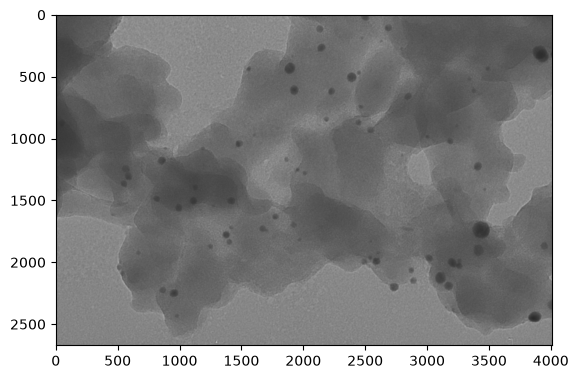

In [9]:
img_array = hs.load(f"{imageToPlot}.dm3").data
print(f"img_array shape : {img_array.shape}, img_array type : {img_array.dtype}")
plt.imshow(img_array, cmap='gray')

In [ ]:
print(f"img_array dtype: {img_array.dtype}")
print(f"label_array dtype: {label_array.dtype}")

In [ ]:
# Remap the values: 1→3, 2→1, 3→2
image_path2 = r'60kX-ss57-Au45Cu55-SiO2-CALC-0008'
imageToPlot2 = AuCuSiO2_Path / image_path2

label_array = np.array(Image.open(f"{imageToPlot2}_lab_mod2.tif"))  # Replace with your label image path


remapped_array = np.copy(label_array)
remapped_array[label_array == 1] = 3  # Green → Red
remapped_array[label_array == 2] = 1  # Blue → Green
remapped_array[label_array == 3] = 2  # Red → Blue

# Plot the remapped array
plt.imshow(remapped_array, cmap=cmap, vmin=1, vmax=3)
remapped_image = Image.fromarray(remapped_array.astype(np.uint8))
remapped_image.save("60kX-ss57-Au45Cu55-SiO2-CALC-0008_lab_mod.tif")

no unasigned pixels
no unasigned pixels


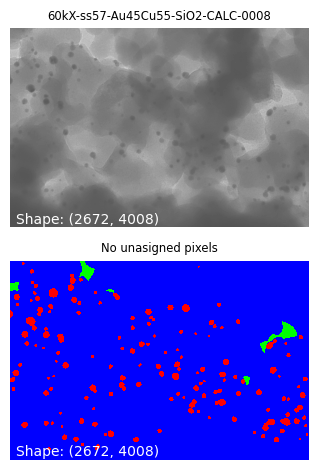

In [8]:


#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0005'
#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0006'
image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0008'

imageToPlot = AuCuSiO2_Path / image_path
st.check_labelling(np.array(Image.open(f"{imageToPlot}_lab_mod.tif")))

binBy2 = False

if binBy2 == True:
    img_array = st.bin_grayscale(hs.load(f"{imageToPlot}.dm3").data)
    label_array = st.bin_labels(np.array(Image.open(f"{imageToPlot}_lab_mod.tif")))
else:
    img_array = hs.load(f"{imageToPlot}.dm3").data
    label_array = np.array(Image.open(f"{imageToPlot}_lab_mod.tif"))

# Define colors for the labeled image
colors = [
    [0, 1, 0, 1],    # Value 1 (green)
    [0, 0, 1, 1],    # Value 2 (blue)
    [1, 0, 0, 1]     # Value 3 (red)
]
cmap = ListedColormap(colors)

# Create a figure with two subplots
fig, axes = plt.subplots(2, 1)

axes[0].imshow(img_array, cmap='gray')
axes[0].axis('off')
axes[0].set_title(image_path, fontsize="small")
axes[0].text(0.02, 0.02, f"Shape: {img_array.shape}",
             transform=axes[0].transAxes,
             color='white', fontsize=10)

axes[1].imshow(label_array, cmap=cmap, vmin=1, vmax=3)
axes[1].axis('off')
axes[1].set_title("Label image", fontsize="small")
axes[1].text(0.02, 0.02, f"Shape: {label_array.shape}",
             transform=axes[1].transAxes,
             color='white', fontsize=10)

plt.tight_layout()
plt.show()